In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
df=pd.read_csv('/content/drive/MyDrive/DataScience/Assignments/Data sets/ABC Company Dataset.csv')

In [7]:
np.random.seed(42)
df['Height']=np.random.randint(150,181,size=len(df))

  **Preprocessing :**
         
         The Height column contained incorrect date-format values.These values were replaced with randomly generated integers between 150 and 180.

In [8]:
df.dtypes

,0
Name,object
Team,object
Number,int64
Position,object
Age,int64
Height,int64
Weight,int64
College,object
Salary,float64


In [ ]:
df['Height'].min()
df['Height'].max()

180

In [ ]:
display(df['Height'].head())

,Height
0,156
1,169
2,178
3,164
4,160


In [ ]:
df.isnull().sum()

,0
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(458, 9)

In [ ]:
df.columns

Index(['Name', 'Team', 'Number', 'Position', 'Age', 'Height', 'Weight',
       'College', 'Salary'],
      dtype='object')

In [ ]:
df.head()

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,156,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,169,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,178,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,164,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,160,231,NaN,5000000.0


In [15]:
for col in df.select_dtypes(include='object').columns:
  print(f"\n{col}:")
  print(df[col].unique().tolist())
  print(df[col].unique().shape)



Name:
['Avery Bradley', 'Jae Crowder', 'John Holland', 'R.J. Hunter', 'Jonas Jerebko', 'Amir Johnson', 'Jordan Mickey', 'Kelly Olynyk', 'Terry Rozier', 'Marcus Smart', 'Jared Sullinger', 'Isaiah Thomas', 'Evan Turner', 'James Young', 'Tyler Zeller', 'Bojan Bogdanovic', 'Markel Brown', 'Wayne Ellington', 'Rondae Hollis-Jefferson', 'Jarrett Jack', 'Sergey Karasev', 'Sean Kilpatrick', 'Shane Larkin', 'Brook Lopez', 'Chris McCullough', 'Willie Reed', 'Thomas Robinson', 'Henry Sims', 'Donald Sloan', 'Thaddeus Young', 'Arron Afflalo', 'Lou Amundson', 'Thanasis Antetokounmpo', 'Carmelo Anthony', 'Jose Calderon', 'Cleanthony Early', 'Langston Galloway', 'Jerian Grant', 'Robin Lopez', "Kyle O'Quinn", 'Kristaps Porzingis', 'Kevin Seraphin', 'Lance Thomas', 'Sasha Vujacic', 'Derrick Williams', 'Tony Wroten', 'Elton Brand', 'Isaiah Canaan', 'Robert Covington', 'Joel Embiid', 'Jerami Grant', 'Richaun Holmes', 'Carl Landry', 'Kendall Marshall', 'T.J. McConnell', 'Nerlens Noel', 'Jahlil Okafor', 'Is

**Data consistency and Integrity check:**

 All columns were checked for appropriate data types,missing values,duplicate records and inconsistent values.Identified 84 missing values in college and 11 missing values in salary.


**Analysis Tasks:**
      
     1. Determine the distribution of employees across each team and calculate the percentage split relative to the total number of employees.

In [ ]:
df['Team'].value_counts()

,count
Team,
New Orleans Pelicans,19
Memphis Grizzlies,18
Utah Jazz,16
Milwaukee Bucks,16
New York Knicks,16
Boston Celtics,15
Los Angeles Clippers,15
Los Angeles Lakers,15
Phoenix Suns,15


In [16]:
team_count=df['Team'].value_counts()
total_count=team_count.sum()
percentage_split=(team_count/total_count)*100
print(percentage_split.round(2))

Team
New Orleans Pelicans      4.15
Memphis Grizzlies         3.93
Utah Jazz                 3.49
Milwaukee Bucks           3.49
New York Knicks           3.49
Boston Celtics            3.28
Los Angeles Clippers      3.28
Los Angeles Lakers        3.28
Phoenix Suns              3.28
Sacramento Kings          3.28
Brooklyn Nets             3.28
Philadelphia 76ers        3.28
Toronto Raptors           3.28
Golden State Warriors     3.28
Indiana Pacers            3.28
Detroit Pistons           3.28
Cleveland Cavaliers       3.28
Chicago Bulls             3.28
Houston Rockets           3.28
San Antonio Spurs         3.28
Atlanta Hawks             3.28
Dallas Mavericks          3.28
Charlotte Hornets         3.28
Miami Heat                3.28
Denver Nuggets            3.28
Washington Wizards        3.28
Portland Trail Blazers    3.28
Oklahoma City Thunder     3.28
Orlando Magic             3.06
Minnesota Timberwolves    3.06
Name: count, dtype: float64


In [ ]:
team_distribution=pd.DataFrame ({'Team':team_count.index,
   'Count':team_count.values,
   'Percentage':percentage_split.values.round(2)})
print(team_distribution)

                      Team  Count  Percentage
0     New Orleans Pelicans     19        4.15
1        Memphis Grizzlies     18        3.93
2                Utah Jazz     16        3.49
3          Milwaukee Bucks     16        3.49
4          New York Knicks     16        3.49
5           Boston Celtics     15        3.28
6     Los Angeles Clippers     15        3.28
7       Los Angeles Lakers     15        3.28
8             Phoenix Suns     15        3.28
9         Sacramento Kings     15        3.28
10           Brooklyn Nets     15        3.28
11      Philadelphia 76ers     15        3.28
12         Toronto Raptors     15        3.28
13   Golden State Warriors     15        3.28
14          Indiana Pacers     15        3.28
15         Detroit Pistons     15        3.28
16     Cleveland Cavaliers     15        3.28
17           Chicago Bulls     15        3.28
18         Houston Rockets     15        3.28
19       San Antonio Spurs     15        3.28
20           Atlanta Hawks     15 

The team-wise distribution shows the number of employess in each team and their respective percentage contribution to the total workforce.The New Orleans Pelicans have the highest number of employees,Minnesota Timberwolves and Orlando Magic have the lowest number of employees.

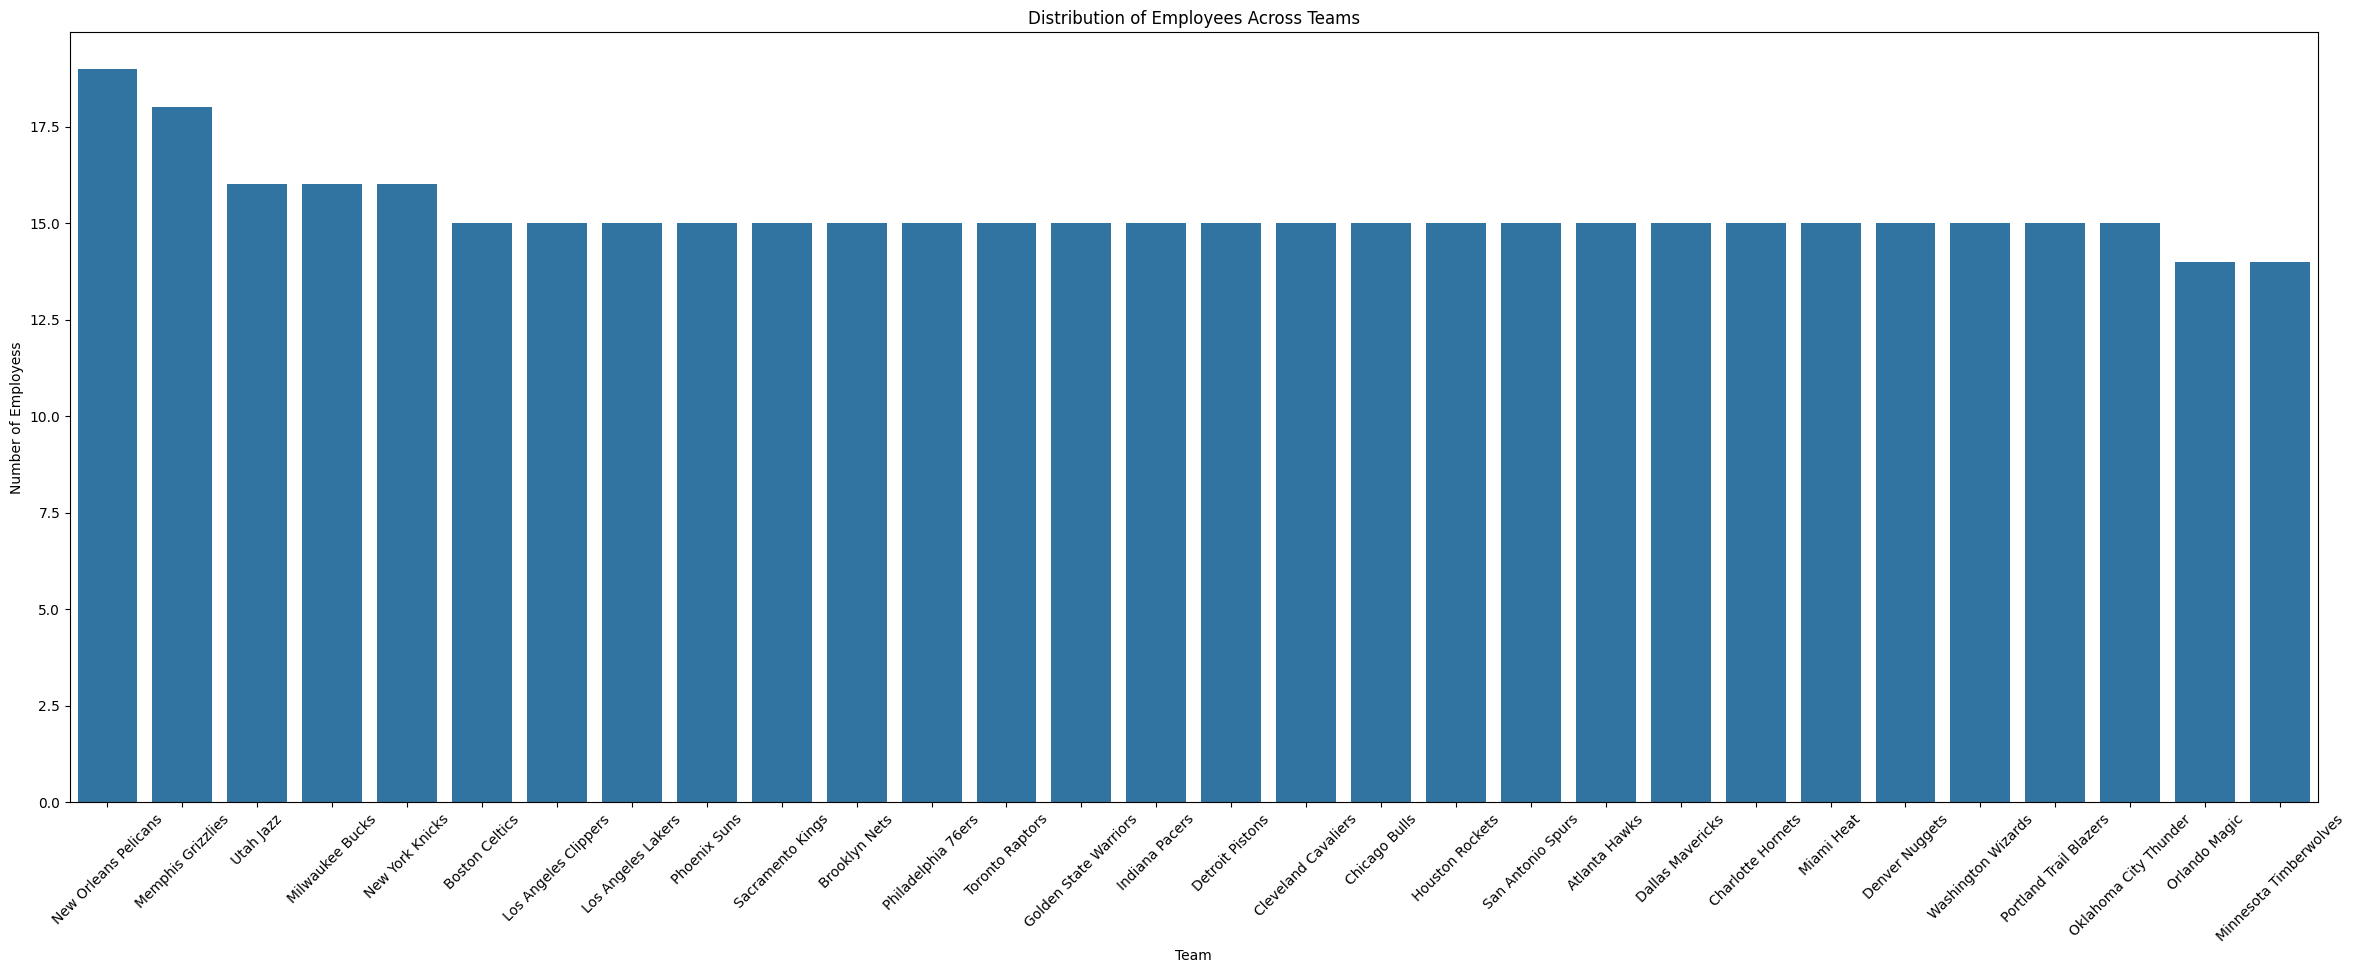

In [ ]:
plt.figure(figsize=(29,10))
sns.barplot(x='Team',y='Count',data=team_distribution)
plt.xlabel('Team')
plt.ylabel('Number of Employess')
plt.title('Distribution of Employees Across Teams')
plt.xticks(rotation=45)
plt.show()

The New Orleans pelicans have the highest number of employees,with 19 employess.It is 4.15 % of the total number of employees.The employee distribution across team is relatively balanced,with only small differences in team size.

 2.Segregate employees based on their positions within the company.

In [ ]:
position_count=df['Position'].value_counts()
total_count=position_count.sum()
Position_percentage=(position_count/total_count)*100
position_distribution=pd.DataFrame ({'Position':position_count.index,
   'Count':position_count.values,
   'Percentage':Position_percentage.values.round(2)})
print(position_distribution)


  Position  Count  Percentage
0       SG    102       22.27
1       PF    100       21.83
2       PG     92       20.09
3       SF     85       18.56
4        C     79       17.25


The position distribution shows the segregation of employees based on their positions with in the company.Most of the employees are in SG catagory.

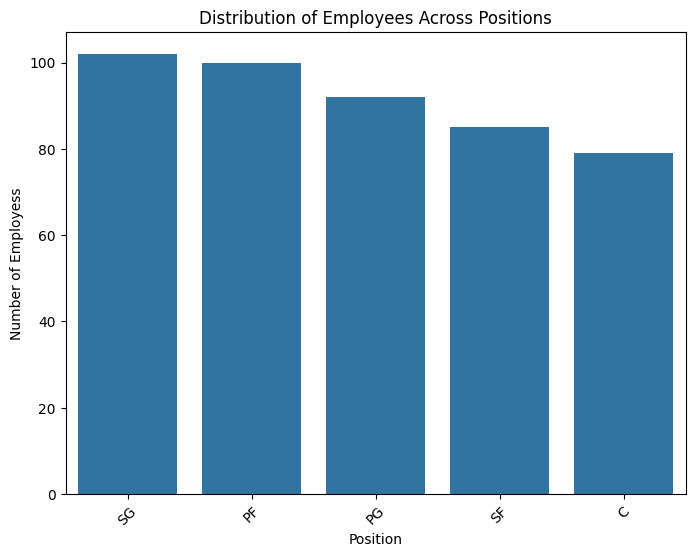

In [ ]:
plt.figure(figsize=(8,6))
sns.barplot(x='Position',y='Count',data=position_distribution)
plt.xlabel('Position')
plt.ylabel('Number of Employess')
plt.title('Distribution of Employees Across Positions')
plt.xticks(rotation=45)
plt.show()

The SG position has the highest employee count,with 102 employees.Whereas the C position has the lowest employee count,with 79 employees.The employee distribution across the five positions is relatively balanced.

3.Identify the predominant age group among employees.




In [ ]:
df['Age'].describe()

,Age
count,458.000000
mean,26.934498
std,4.400128
min,19.000000
25%,24.000000
50%,26.000000
75%,30.000000
max,40.000000


The employees' ages ranges from 19-40 years,with 19 being the minimum age and 40 being the maximum age.

In [ ]:
bins=[0,19,25,30,35,40]
labels=['0-19','20-25','26-30','31-35','36-40']
df['Age_Group']=pd.cut(df['Age'],bins=bins,labels=labels)
count=df['Age_Group'].value_counts().sort_index()
print(count)





Age_Group
0-19       2
20-25    198
26-30    167
31-35     68
36-40     23
Name: count, dtype: int64


In [ ]:
print("Predominent age group :", count.idxmax())

Predominent age group : 20-25


The predominant age group among employees is 20-25 years, with 198 employees.

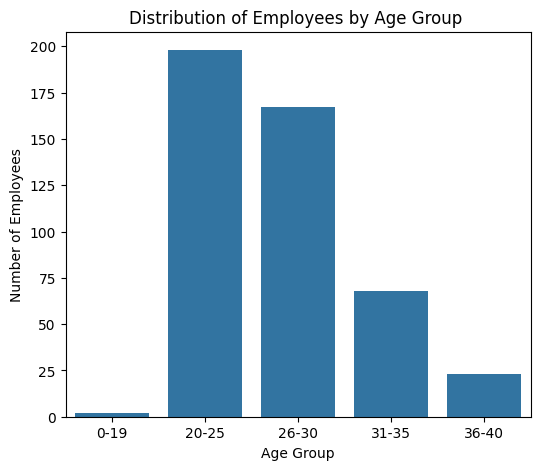

In [ ]:
plt.figure(figsize=(6,5))
sns.barplot(x=count.index,y=count.values)
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
plt.title('Distribution of Employees by Age Group ')
plt.show()

The majority of employees belong to the 20-25 age group,with 198 employees(43.23% of the total employees).The 0-19 age group has the lowest representation,with only 2 employees.

4.Discover which team and position have the highest salary expenditure.

In [ ]:
# Team wise salary expenditure
team_salary=df.groupby('Team')['Salary'].sum()
print(team_salary.sort_values(ascending=False))
position_salary=df.groupby('Position')['Salary'].sum()
print(position_salary.sort_values(ascending=False))
print("The team with highest salary expenditure:")
print(team_salary.idxmax(),team_salary.max())
print("The position with highest salary expenditure:")
print(position_salary.idxmax(),position_salary.max())


Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberwolves     59709697.0
Boston 

Among all teams,the Cleveland Cavaliers have the highest salary expenditure.

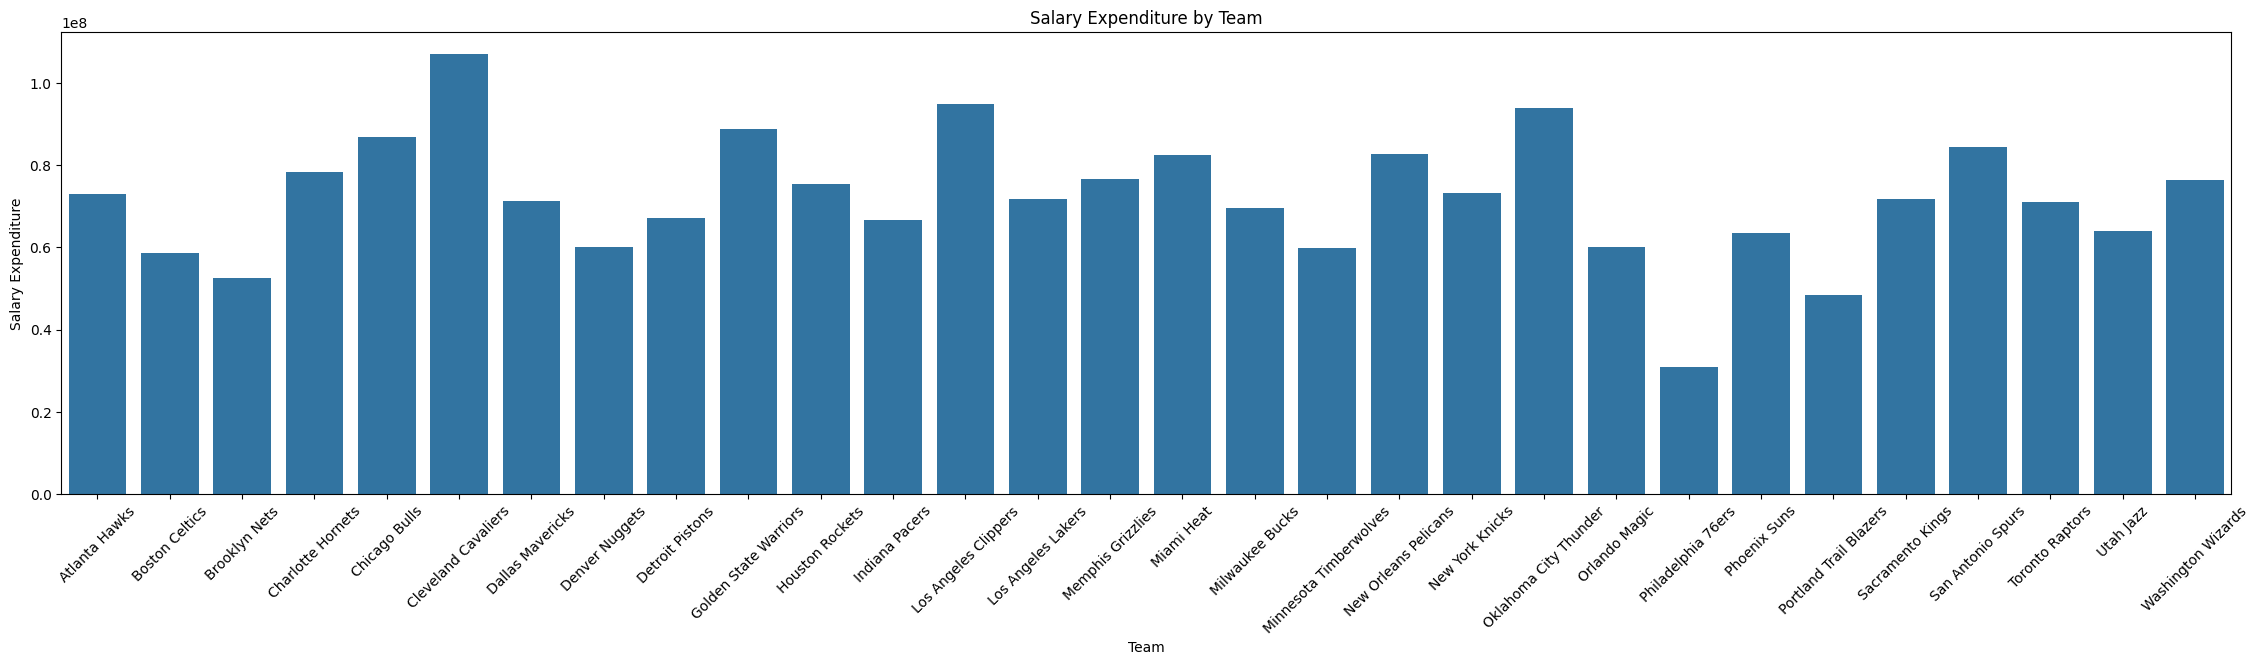

In [ ]:
plt.figure(figsize=(28,6))
sns.barplot(x=team_salary.index,y=team_salary.values)
plt.xlabel('Team')
plt.ylabel('Salary Expenditure')
plt.title('Salary Expenditure by Team')
plt.xticks(rotation=45)
plt.show()

The salary expenditure varies across teams with,the Cleveland Cavaliers  having the highest total salary expenditure and Philadelphia 76ers having the lowest.

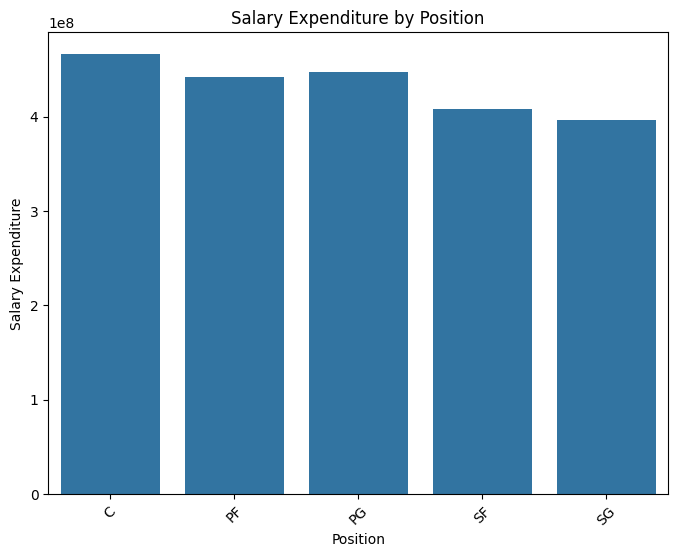

In [ ]:
plt.figure(figsize=(8,6))
sns.barplot(x=position_salary.index,y=position_salary.values)
plt.xlabel('Position')
plt.ylabel('Salary Expenditure')
plt.title('Salary Expenditure by Position')
plt.xticks(rotation=45)
plt.show()

Salary expenditure is relatively similar across the five positions.C,PF and PG have comparatively higher salary expenditure.Position C has relatively high salary expenditure and SG has the lowest salary expenditure.

5.Investigate if there's any correlation between age and salary, and
represent it visually.

In [ ]:
correlation=df['Age'].corr(df['Salary'])
print("Correlation between Age and Salary:",correlation)

Correlation between Age and Salary: 0.21400941226570971


The correlation between age and salary is 0.214,indicating a weak positive correlation.This suggests that salary tends to increase slightly with age,but the relationship is not strong.

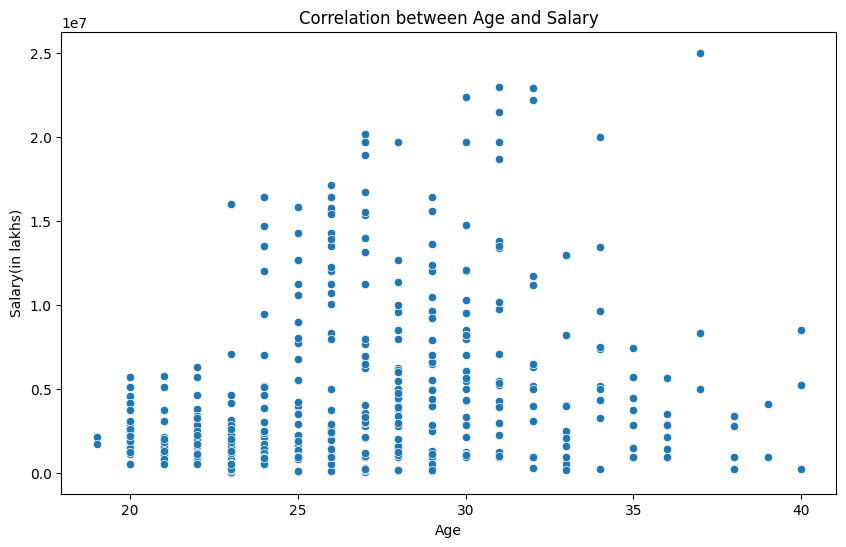

In [17]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Age',y='Salary',data=df)
plt.xlabel('Age')
plt.ylabel('Salary(in lakhs)')
plt.title('Correlation between Age and Salary')
plt.show()

Salary values are widely scattered across different age groups.Employees of the same age group have differnt salary levels.Higher salary values are visible mainly among employees aged around 25-32.There is no linear relationship between age and salary.